# 🛠️ Arabic Text Preprocessing & GPT-4o Targeted Data Augmentation
**Project:** Persuasion Technique Detection in Arabic Text (ArAIEval Task 1)

This notebook implements an end-to-end data preparation workflow:
1. **Format Harmonization:** Standardize tweets and news paragraphs to minimize domain and stylistic discrepancies.
2. **Special Token Handling:** Translate `LINK` keywords and URLs to Arabic (`رابط`), clean `@USER` mentions, and normalize `#hashtags`.
3. **Emoji Mapping:** Map visual emojis to descriptive Arabic terms (using an Arabic news/social mapping dictionary + `emoji.demojize(language='ar')`).
4. **Punctuation & Character Filtering:** Retain only meaningful rhetorical marks (`?`, `!`, `؟`) while stripping all other symbols, Latin words, and numbers.
5. **GPT-4o Targeted Data Augmentation:** Use OpenAI's GPT-4o with structured JSON outputs to generate realistic examples for underrepresented minority persuasion classes (e.g., *Straw Man*, *Appeal to Popularity*, *Whataboutism*, *Red Herring*).
6. **Export Cleaned Datasets:** Generate clean, unified `.jsonl` files ready for fine-tuning transformers (MARBERTv2, AraBERTv0.2).


In [7]:
import os
import re
import json
import getpass
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import emoji
from tqdm.auto import tqdm
from openai import OpenAI
from pathlib import Path as p

DIR = p(r'C:\\Users\\pc\\Desktop\\M2 BDIO\\LLMs\\Decetction-Persuation\\data')

df_1b_train = pd.read_json(DIR / "task1B_train.jsonl", lines=True, encoding="utf-8")
df_1b_dev   = pd.read_json(DIR / "task1B_dev.jsonl", lines=True, encoding="utf-8")
df_1b_test  = pd.read_json(DIR / "task1B_test.jsonl", lines=True, encoding="utf-8")

## 1. 🧹 Arabic Text Preprocessing Pipeline
We design a multi-stage cleaning function `clean_arabic_text()` tailored to the ArAIEval dataset:
- **`LINK` & URL Translation:** Replace `LINK` and URLs with Arabic `رابط` before Latin removal so reference semantics are retained.
- **User Mentions & Retweets:** Remove `RT` markers and normalize `@USER` / `@mentions`.
- **Hashtags:** Convert `#وسم_موضوع` into `وسم موضوع` to preserve lexical keywords without social noise.
- **Emoji Translation:** Convert visual emojis (e.g. 🔴, ⚠️, 💔) into descriptive Arabic equivalents so models retain emotional and rhetorical cues.
- **Punctuation Filtering:** Preserve only question and exclamation marks (`!`, `?`, `؟`) and remove commas, colons, quotes, dashes, etc.
- **Latin & Digit Stripping:** Eliminate English/Latin characters and numbers (Western `0-9` and Eastern Arabic `٠-٩`).
- **Orthographic Normalization:** Strip tatweel/kashida (`ـ`) and normalize excessive whitespace.


In [8]:
# Custom dictionary for high-frequency media and tweet emojis in Arabic
EMOJI_ARABIC_MAPPING = {
    '🔴': ' عاجل ',
    '🚨': ' تنبيه عاجل ',
    '💔': ' حزن ',
    '👍': ' إعجاب ',
    '👎': ' استنكار ',
    '✌️': ' نصر ',
    '🔥': ' اشتعال ',
    '⚠️': ' تحذير ',
    '📢': ' إعلان ',
    '📌': ' ملاحظة ',
    '🎯': ' هدف ',
    '⚡': ' عاجل ',
    '😡': ' غضب ',
    '👏': ' تصفيق ',
    '🌹': ' تحية ',
}

def clean_arabic_text(text: str) -> str:
    """
    Cleans and standardizes Arabic text (both news paragraphs and tweets).
    Harmonizes formatting, translates 'LINK', maps emojis, strips Latin and digits,
    and retains only rhetorical punctuation marks (? ! ؟).
    """
    if not isinstance(text, str) or not text.strip():
        return ''

    # 1. Translate 'LINK' and web URLs to Arabic 'رابط' before Latin removal
    text = re.sub(r'\bLINK\b', 'رابط', text, flags=re.IGNORECASE)
    text = re.sub(r'https?://\S+', 'رابط', text)

    # 2. Handle Retweets (RT) and @USER mentions
    text = re.sub(r'\bRT\b', ' ', text)
    text = re.sub(r'@USER\b', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)

    # 3. Clean hashtags: remove '#' and replace underscores with spaces
    text = re.sub(r'#([^\s#]+)', lambda m: ' ' + m.group(1).replace('_', ' ') + ' ', text)

    # 4. Map Emojis to descriptive Arabic words
    for emo, ar_repr in EMOJI_ARABIC_MAPPING.items():
        if emo in text:
            text = text.replace(emo, ar_repr)
    # Demojize remaining emojis using Arabic definitions
    text = emoji.demojize(text, language='ar')
    # Clean emoji delimiters (:اسم_الإيموجي: -> اسم الإيموجي)
    text = re.sub(r':([^\s:]+):', lambda m: ' ' + m.group(1).replace('_', ' ') + ' ', text)

    # 5. Remove Latin words and characters
    text = re.sub(r'[a-zA-Z]+', ' ', text)

    # 6. Remove numbers (Western 0-9 and Eastern Arabic numerals ٠-٩)
    text = re.sub(r'[0-9\u0660-\u0669]+', ' ', text)

    # 7. Retain only Arabic letters, whitespace, and rhetorical punctuation (? ! ؟)
    # Arabic unicode block: \u0600-\u06FF, \u0750-\u077F, \u08A0-\u08FF
    text = re.sub(r'[^\u0600-\u06FF\s?!؟]', ' ', text)

    # 8. Remove tatweel / kashida (ـ)
    text = re.sub(r'\u0640+', '', text)

    # 9. Normalize multiple consecutive punctuation (e.g., !!!! -> !, ؟؟؟ -> ؟)
    text = re.sub(r'[!]+', ' ! ', text)
    text = re.sub(r'[\?؟]+', ' ؟ ', text)

    # 11 . mapping the ? an ! to arabic text 
    text = re.sub(r'!', 'تعجب', text)
    text = re.sub(r'؟', 'استفهام', text)

    # 10. Normalize consecutive spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

## 2. 📁 Batch Preprocessing of Datasets
We apply the cleaning function across all splits (`train`, `dev`, and `test`) and save the output as `_cleaned.jsonl` files in the data directory.


In [11]:
def preprocess_df(
    df: pd.DataFrame, output_path: Path | str = None
) -> pd.DataFrame:
    """Applies clean_arabic_text to a DataFrame and optionally exports it as a jsonl file."""
    df_cleaned = df.copy()
    df_cleaned["text"] = df_cleaned["text"].apply(clean_arabic_text)

    # Optionally save to jsonl if an output path is provided
    if output_path is not None:
        df_cleaned.to_json(
            output_path, orient="records", lines=True, force_ascii=False
        )
        print(
            f"Processed {len(df_cleaned):,} records -> {Path(output_path).name}"
        )

    return df_cleaned


# Clean your loaded DataFrames directly
df_1b_train_cleaned = preprocess_df(
    df_1b_train, DIR / "task1B_train_cleaned.jsonl"
)
df_1b_dev_cleaned = preprocess_df(df_1b_dev, DIR / "task1B_dev_cleaned.jsonl")
df_1b_test_cleaned = preprocess_df(
    df_1b_test, DIR / "task1B_test_cleaned.jsonl"
)


Processed 2,427 records -> task1B_train_cleaned.jsonl
Processed 259 records -> task1B_dev_cleaned.jsonl
Processed 503 records -> task1B_test_cleaned.jsonl


## 3. 📊 Minority Class Analysis for Augmentation
In Task 1B, classes suffer from severe imbalance. Identifying tail labels allows us to generate targeted synthetic data via GPT-4o.


Total training samples: 2,427
Total distinct labels: 24

Minority classes (< 35 samples): 10
                           Technique  Count  Percentage
23              Appeal_to_Popularity      2    0.082406
22                         Straw_Man      6    0.247219
21                       Red_Herring      8    0.329625
20                      Whataboutism      9    0.370828
19                    Appeal_to_Time     10    0.412031
18              Guilt_by_Association     13    0.535641
17                        Repetition     25    1.030078
16               Conversation_Killer     28    1.153688
15           False_Dilemma-No_Choice     32    1.318500
14  Consequential_Oversimplification     33    1.359703


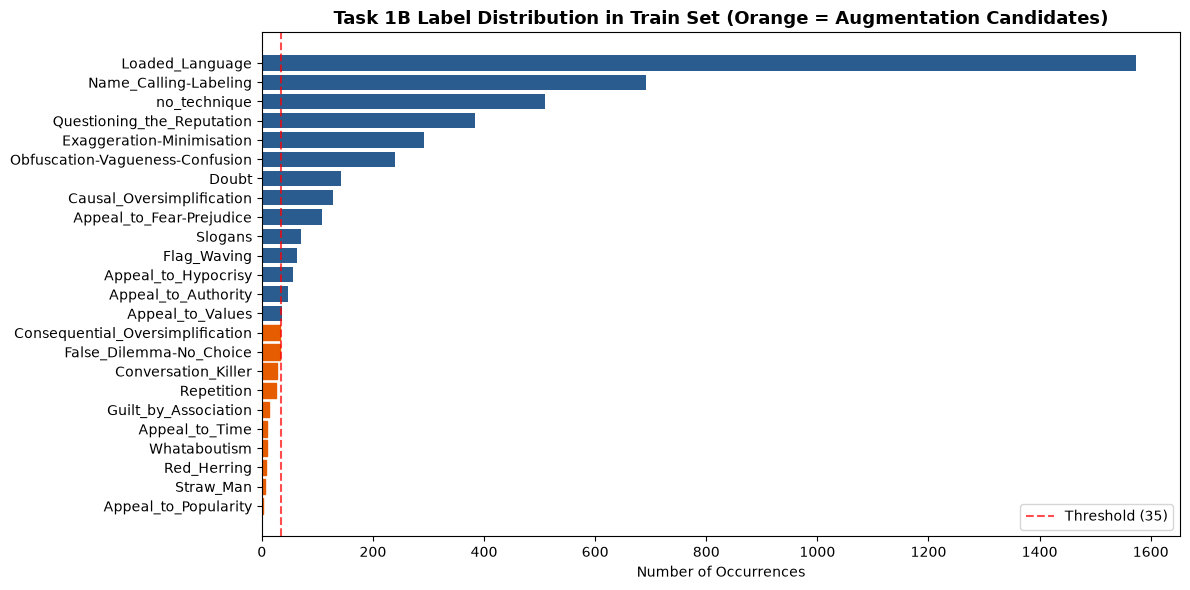

In [14]:
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

# 1. Use the in-memory cleaned training DataFrame directly
df_train = df_1b_train_cleaned

# 2. Count label frequencies
label_counter = Counter()
for labels in df_train["labels"]:
    label_counter.update(labels)

df_labels = pd.DataFrame(
    label_counter.most_common(), columns=["Technique", "Count"]
)
df_labels["Percentage"] = (df_labels["Count"] / len(df_train)) * 100

print(f"Total training samples: {len(df_train):,}")
print(f"Total distinct labels: {len(df_labels)}")

# 3. Identify minority classes with fewer than 35 occurrences
MINORITY_THRESHOLD = 35
minority_df = df_labels[df_labels["Count"] < MINORITY_THRESHOLD].sort_values(
    by="Count"
)
print(f"\nMinority classes (< {MINORITY_THRESHOLD} samples): {len(minority_df)}")
print(minority_df)

# 4. Plot class distribution (Orange = Augmentation Candidates)
plt.figure(figsize=(12, 6), dpi=100)
bars = plt.barh(
    df_labels["Technique"][::-1], df_labels["Count"][::-1], color="#2b5c8f"
)

for i, bar in enumerate(bars):
    if df_labels["Count"].iloc[len(df_labels) - 1 - i] < MINORITY_THRESHOLD:
        bar.set_color("#e65c00")  # Highlight minority classes

plt.axvline(
    x=MINORITY_THRESHOLD,
    color="red",
    linestyle="--",
    alpha=0.7,
    label=f"Threshold ({MINORITY_THRESHOLD})",
)
plt.title(
    "Task 1B Label Distribution in Train Set (Orange = Augmentation"
    " Candidates)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Number of Occurrences")
plt.legend()
plt.tight_layout()
plt.show()


## 4. 🤖 GPT-4o Targeted Data Augmentation
To balance the minority classes, we use GPT-4o to generate authentic Arabic texts (news paragraphs and tweets) that naturally demonstrate each target persuasion technique.

### Taxonomy Definitions Reference:
- **`Appeal_to_Popularity`:** Arguing an idea is correct because many people agree with it (bandwagon).
- **`Straw_Man`:** Misrepresenting an opponent's argument to make it easier to attack.
- **`Red_Herring`:** Introducing irrelevant information to divert attention from the main issue.
- **`Whataboutism`:** Deflecting a critique by charging hypocrisy or raising a counter-accusation.
- **`Appeal_to_Time`:** Claiming something is urgent or obsolete purely based on time.
- **`Guilt_by_Association`:** Discrediting an idea or person based on an associated unpopular group.
- **`Repetition`:** Repeating words or themes persistently to influence perception.
- **`Conversation_Killer`:** Thought-terminating clichés designed to abruptly shut down discussion.


In [17]:
# Setup OpenAI Client
# Provide your OpenAI API Key when prompted, or set the OPENAI_API_KEY environment variable.
api_key = os.environ.get('OPENAI_API_KEY')
if not api_key:
    api_key = getpass.getpass('Enter your OpenAI API Key: ')

client = OpenAI(api_key=api_key)
print('OpenAI client successfully initialized!')


OpenAI client successfully initialized!


In [19]:
PERSUASION_DEFINITIONS = {
    'Appeal_to_Popularity': 'استخدام حجة أن الفكرة صحيحة لأن الأغلبية تدعمها (مغالطة عربة الموسيقى / الاحتكام للعامة)',
    'Straw_Man': 'تشويه حجة الخصم أو تضخيمها بشكل مغلوط لتسهيل الهجوم عليها ودحضها (رجل القش)',
    'Red_Herring': 'طرح موضوع جانبي غير ذي صلة لتشتيت الانتباه عن القضية الأصلية (الفسيخ الأحمر)',
    'Whataboutism': 'تحويل مسار النقد بتوجيه اتهام مقابل أو إثارة قضية أخرى لتبرير الخطأ (وماذا عن...؟)',
    'Appeal_to_Time': 'الزعم بأن فكرة ما صالحة أو خاطئة بحكم الوقت والسرعة أو لأنها قديمة/جديدة',
    'Guilt_by_Association': 'تشويه فكرة أو شخص بسبب وجود صلة بمجموعة غير مرغوبة (الذنب بالتبعية)',
    'Repetition': 'التكرار المستمر لنفس الفكرة أو العبارة لترسيخها في أذهان الجمهور',
    'Conversation_Killer': 'عبارات قطعية مبتذلة تهدف إلى إيقاف النقاش والتفكير (مثل: هذا هو الواقع، لا فائدة من الكلام)',
    'False_Dilemma-No_Choice': 'حصر المشكلة في خيارين متطرفين فقط دون النظر لبدائل (إما معنا أو ضدنا)',
    'Consequential_Oversimplification': 'الزعم بأن خطوة واحدة ستؤدي حتماً لكارثة متسلسلة غير مثبتة (المنحدر الزلق)',
}

def generate_augmented_samples(target_label: str, num_samples: int = 5, client: OpenAI = client) -> list:
    """
    Uses GPT-4o with structured JSON output to generate realistic Arabic texts
    exhibiting the specified persuasion technique.
    """
    definition = PERSUASION_DEFINITIONS.get(target_label, 'أسلوب إقناعي خطابي')
    
    system_prompt = """أنت خبير في اللغويات الحاسوبية وتحليل الخطاب الإعلامي العربي وأساليب الإقناع والدعاية (ArAIEval / SemEval Taxonomy).
مهمتك توليد نصوص باللغة العربية (فقرات إخبارية أو تغريدات) توظف أسلوباً إقناعياً محدداً بدقة وبشكل طبيعي جداً.
يجب أن تعيد النتيجة بصيغة JSON حصراً وفق البنية المطلوبة."""

    user_prompt = f"""ولد عدد {num_samples} نصوص عربية متنوعة (بعضها أسلوب تغريدة وبعضها أسلوب فقرة صحفية) تستخدم الأسلوب التالي:
الأسلوب المستهدف: {target_label}
تعريف الأسلوب: {definition}

متطلبات التوليد:
1. أن تكون النصوص واقعية ومماثلة للأخبار أو منشورات التواصل الاجتماعي حول مواضيع سياسية، اقتصادية، أو اجتماعية.
2. أن يوظف النص الأسلوب المطلوب بوضوح وبلا تكلف.
3. أعد قائمة كائنات JSON تحت المفتاح 'samples' بحيث يحتوي كل كائن على:
   - 'text': النص العربي
   - 'type': 'tweet' أو 'paragraph'
   - 'labels': قائمة تحتوي على ['{target_label}'] مع أي أسلوب إضافي متلازم طبيعياً مثل 'Loaded_Language' إذا كان النص يحتوي على لغة عاطفية مشحونة."""

    try:
        response = client.chat.completions.create(
            model='gpt-4o',
            messages=[
                {'role': 'system', 'content': system_prompt},
                {'role': 'user', 'content': user_prompt}
            ],
            response_format={'type': 'json_object'},
            temperature=0.7,
        )
        data = json.loads(response.choices[0].message.content)
        samples = data.get('samples', [])
        return samples
    except Exception as e:
        print(f'Error generating samples for {target_label}: {e}')
        return []


### Execute Data Augmentation on Target Minority Classes
We generate supplementary training examples for each minority technique. Each generated text is then routed through our `clean_arabic_text()` pipeline to ensure consistent formatting.


In [20]:
# Choose minority labels to augment and desired samples per label
AUGMENT_TARGETS = [
    'Appeal_to_Popularity',
    'Straw_Man',
    'Red_Herring',
    'Whataboutism',
    'Appeal_to_Time',
    'Guilt_by_Association',
    'Conversation_Killer',
    'False_Dilemma-No_Choice',
    'Consequential_Oversimplification'
]

SAMPLES_PER_TECHNIQUE = 12  # Adjust as needed
augmented_records = []
current_id = 90001

print(f'Starting augmentation for {len(AUGMENT_TARGETS)} techniques ({SAMPLES_PER_TECHNIQUE} samples each)...')

for target in tqdm(AUGMENT_TARGETS, desc='Augmenting techniques'):
    generated = generate_augmented_samples(target, num_samples=SAMPLES_PER_TECHNIQUE, client=client)
    for sample in generated:
        cleaned_text = clean_arabic_text(sample.get('text', ''))
        if cleaned_text:
            augmented_records.append({
                'id': f'AUG_{current_id}',
                'text': cleaned_text,
                'labels': sample.get('labels', [target]),
                'type': sample.get('type', 'paragraph')
            })
            current_id += 1

print(f'Successfully generated and cleaned {len(augmented_records)} synthetic samples!')


Starting augmentation for 9 techniques (12 samples each)...


Augmenting techniques: 100%|██████████| 9/9 [00:52<00:00,  5.80s/it]

Successfully generated and cleaned 108 synthetic samples!


## 5. 💾 Merge and Export Final Augmented Dataset
Combine the original cleaned training data with the newly generated synthetic samples, inspect the new label counts, and save to `data/task1B_train_cleaned_augmented.jsonl`.


In [21]:
from collections import Counter
from IPython.display import display
import pandas as pd

# 1. Convert augmented records to a DataFrame
df_augmented = pd.DataFrame(augmented_records)

# 2. Concatenate the original cleaned train DataFrame with the augmented DataFrame
df_1b_train_augmented = pd.concat(
    [df_1b_train_cleaned, df_augmented], ignore_index=True
)

# 3. Save directly to JSONL using pandas
output_augmented_path = DIR / "task1B_train_cleaned_augmented.jsonl"
df_1b_train_augmented.to_json(
    output_augmented_path, orient="records", lines=True, force_ascii=False
)

print(f"Original samples:  {len(df_1b_train_cleaned):,}")
print(f"Augmented samples: {len(df_augmented):,}")
print(
    f"Final merged dataset: {len(df_1b_train_augmented):,} samples saved to"
    f" {output_augmented_path.name}"
)

# 4. Compare label frequencies Before vs After
before_counts = Counter(
    label for labels in df_1b_train_cleaned["labels"] for label in labels
)
after_counts = Counter(
    label for labels in df_1b_train_augmented["labels"] for label in labels
)

comparison_df = (
    pd.DataFrame(
        {"Before Augmentation": before_counts, "After Augmentation": after_counts}
    )
    .fillna(0)
    .astype(int)
)

comparison_df["Gain"] = (
    comparison_df["After Augmentation"] - comparison_df["Before Augmentation"]
)

# Display comparison for the augmented techniques
display(comparison_df.loc[AUGMENT_TARGETS])


Original samples:  2,427
Augmented samples: 108
Final merged dataset: 2,535 samples saved to task1B_train_cleaned_augmented.jsonl


,Before Augmentation,After Augmentation,Gain
Appeal_to_Popularity,2,14,12
Straw_Man,6,18,12
Red_Herring,8,20,12
Whataboutism,9,21,12
Appeal_to_Time,10,22,12
Guilt_by_Association,13,25,12
Conversation_Killer,28,40,12
False_Dilemma-No_Choice,32,44,12
Consequential_Oversimplification,33,45,12
